# Human video vs robot video for a robot world model

Two world models, same code, same compute and the same number of training frames; only the video differs:
- `wm-phone`: human videos filmed with a phone (`batgre/h2r-phone`);
- `wm-robots`: real robot videos (`batgre/h2r-robots-1h30`), the first videos of a seeded shuffle up to the same
  number of frames.

Each gets a controller trained on the same robosuite episodes (Panda, Lift, `batgre/h2r-sim-v3`), then the world models'
predictions and the controllers are evaluated.

Run the cells in order. Runs go to Drive (`MyDrive/h2r/outputs`): after a disconnection, run the cells again,
trainings continue where they stopped and finished evaluations are skipped.

**Setup** (2 min). Clones or updates the repository and installs the environment.

In [1]:
# colab
!pip install -q uv
%cd /content
![ -d human-to-robot ] || git clone https://github.com/batgr/human-to-robot
%cd /content/human-to-robot
!git pull && uv sync

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.3/17.3 MB 108.5 MB/s eta 0:00:0000:0100:01
/content
Cloning into 'human-to-robot'...
remote: Enumerating objects: 406, done.
remote: Counting objects: 100% (406/406), done.
remote: Compressing objects: 100% (210/210), done.
remote: Total 406 (delta 214), reused 345 (delta 153), pack-reused 0 (from 0)
Receiving objects: 100% (406/406), 276.96 KiB | 6.29 MiB/s, done.
Resolving deltas: 100% (214/214), done.
/content/human-to-robot
Already up to date.
Using CPython 3.13.15 interpreter at: /usr/bin/python3
Creating virtual environment at: .venv
Resolved 114 packages in 1ms
⠙ Preparing packages... (0/107)                                                 warning: `build_system.requires = ["uv-build>=0.9.26,<0.10"]` does not contain the current uv version 0.13.1
Prepared 107 packages in 25.49s                                          
Installed 107 packages in 330ms                             
 + absl-py==2.5.1
 + annotated-doc==0.0.5
 + annotated

**Keys and Drive.** Asks for the Hugging Face token and the W&B key, links `outputs/` to Drive.

In [2]:
# colab
import os
from getpass import getpass

from google.colab import drive

os.environ["HF_TOKEN"] = getpass("HF token: ")
os.environ["WANDB_API_KEY"] = getpass("W&B key: ")
os.environ["MUJOCO_GL"] = "egl"  # offscreen rendering for robosuite
drive.mount("/content/drive")
!mkdir -p /content/drive/MyDrive/h2r/outputs && ln -sfn /content/drive/MyDrive/h2r/outputs outputs

Mounted at /content/drive


**Settings.** One run = one `RUN` suffix on every output name, so runs never overwrite each other.
- `H`: the world models are trained and validated on `H` steps (`rollout_steps.end`, `val_horizon`);
  the context stays at 3 frames. Run 1: `RUN = ""`, `H = 5`; run 2: `RUN = "-h2"`, `H = 2`.
- `PHONE_REV`: the version of the phone videos, pinned. Run 1: `668913068cc7` (65 training videos, 2,580 frames);
  run 2: `815bfb769aa6` (124 training videos, 4,181 frames, 20.5 min in all).
- `ROBOT_VIDEOS`: as many robot videos as needed to match the phone videos' training frames (102, then 173).
- Steps: about 60 passes over the world models' clips and 17 over the controllers' transitions.

In [ ]:
import json

from IPython.display import Image, display

RUN, H = "-h2", 2
# run 1: "668913068cc77e2cb195a8b3a88a4d87fd317fb1", 102 (2,580 phone and 2,587 robot training frames, 12.2 min of phone video)
PHONE_REV, ROBOT_VIDEOS = "815bfb769aa6fc2059fe746381473915a2fb665d", 173  # run 2: 4,181 and 4,183 frames, 20.5 min
PHONE = "data.root=data/h2r-phone/ data.hf_repo=batgre/h2r-phone"
ROBOTS = f"data.root=data/h2r-robots-1h30/ data.hf_repo=batgre/h2r-robots-1h30 data.max_videos={ROBOT_VIDEOS}"
WM_STEPS, WM_EVAL, CTRL_STEPS = 1000, 50, 4000

## 1. Data

**Downloads the videos** (a few minutes): the phone frames (without the raw videos) and the robot frames.

In [4]:
!uv run hf download batgre/h2r-phone --repo-type dataset --revision {PHONE_REV} --local-dir data/h2r-phone --exclude "raw/*"
!uv run hf download batgre/h2r-robots-1h30 --repo-type dataset --local-dir data/h2r-robots-1h30

Hint: The `hf-cli` skill is not installed. Run `hf skills add -g` to teach your AI agents how to use the `hf` CLI.

✓ Downloaded
  path: /content/human-to-robot/data/h2r-phone



✓ Downloaded
  path: /content/human-to-robot/data/h2r-robots-1h30




## 2. World models

**Trains both world models** (about 10-20 min each). Every 50 steps the log prints the validation on the model's own
videos:
- `tf`, `ro`: prediction errors (one step with the true past, several steps on its own predictions); should go down;
- `skill_h1..hH`: 1 - error / error of repeating the last frame, h = 1..H steps ahead; above 0 = better than no change;
- `controllability`: how much the prediction depends on the latent action (0 = the action is ignored);
- `rank`, `active_dims`: richness of the states and of the latent actions (falling to a few = collapse);
- `straightness`: about -0.3 for an untrained model; higher = smoother latent trajectories.

`best.pt` keeps the step with the best mean skill.

In [5]:
!uv run h2r train --set name=wm-phone{RUN} {PHONE} rollout_steps.end={H} val_horizon={H} iterations={WM_STEPS} eval_every={WM_EVAL}
!uv run h2r train --set name=wm-robots{RUN} {ROBOTS} rollout_steps.end={H} val_horizon={H} iterations={WM_STEPS} eval_every={WM_EVAL}





wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from WANDB_API_KEY.
wandb: Currently logged in as: grevy-batsotsa (grevy-batsotsa-esme) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: ⢿ Waiting for wandb.init()...
wandb: ⣻ Waiting for wandb.init()...
wandb: ⣽ Waiting for wandb.init()...
wandb: ⣾ Waiting for wandb.init()...
wandb: ⣷ setting up run 3cep59cw (0.5s)
wandb: ⣯ setting up run 3cep59cw (0.5s)
wandb: ⣟ setting up run 3cep59cw (0.5s)
wandb: ⡿ setting up run 3cep59cw (0.5s)
wandb: ⢿ setting up run 3cep59cw (0.5s)
wandb: ⣻ setting up run 3cep59cw (1.0s)
wandb: ⣽ setting up run 3cep59cw (1.0s)
wandb: ⣾ setting up run 3cep59cw (1.0s)
wandb: ⣷ setting up run 3cep59cw (1.0s)
wandb: ⣯ setting up run 3cep59cw (1.0s)
wandb: ⣟ setting up run 3cep59cw (1.5s)
wandb: ⡿ setting up run 3cep59cw (1.5s)
wandb: Tracking run with wandb version 0.30.0
wandb: Run data is saved locally in outputs/wm-phone-h2/wandb/run-20261016_202122-3cep59cw
wandb:

**Training curves** of both world models: every loss and validation metric against the step (`curves.png`).

step 1000/1000 K 2 | loss 1.1311 | tf 0.1520 | ro 0.2143 | kl 9.3286 | sigreg 8.3906 | skill_h1 0.1723 | skill_h2 0.2941 | skill 0.2332 | controllability 0.3992 | rank 77.2926 | straightness -0.2129 | active_dims 89.0000
done | best val skill 0.2332


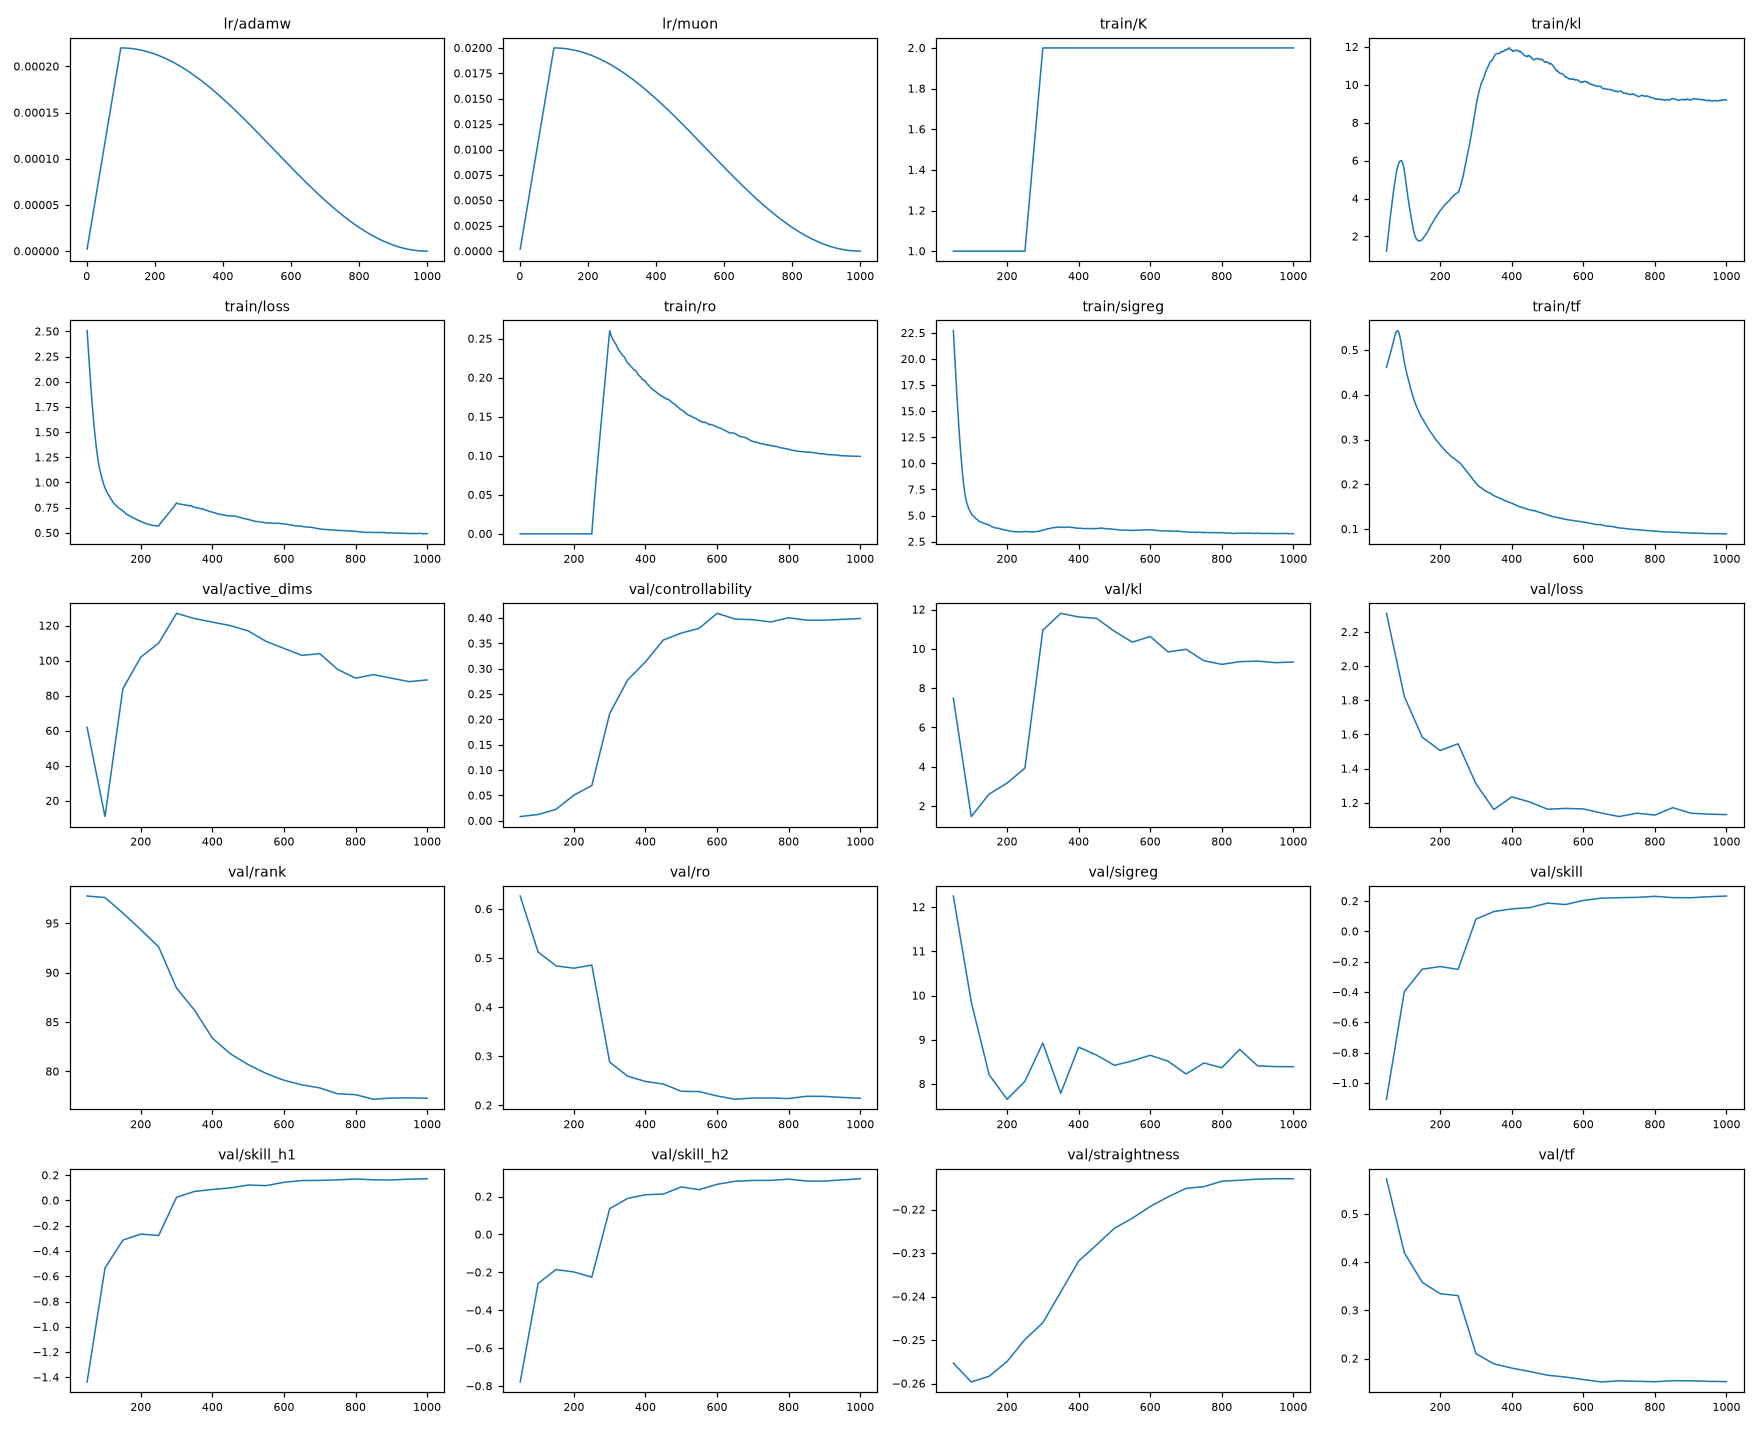

step 1000/1000 K 2 | loss 1.0042 | tf 0.1658 | ro 0.2570 | kl 2.4560 | sigreg 6.4359 | skill_h1 -0.5881 | skill_h2 -0.6896 | skill -0.6389 | controllability 0.0971 | rank 86.9986 | straightness -0.2396 | active_dims 81.0000
done | best val skill -0.5030


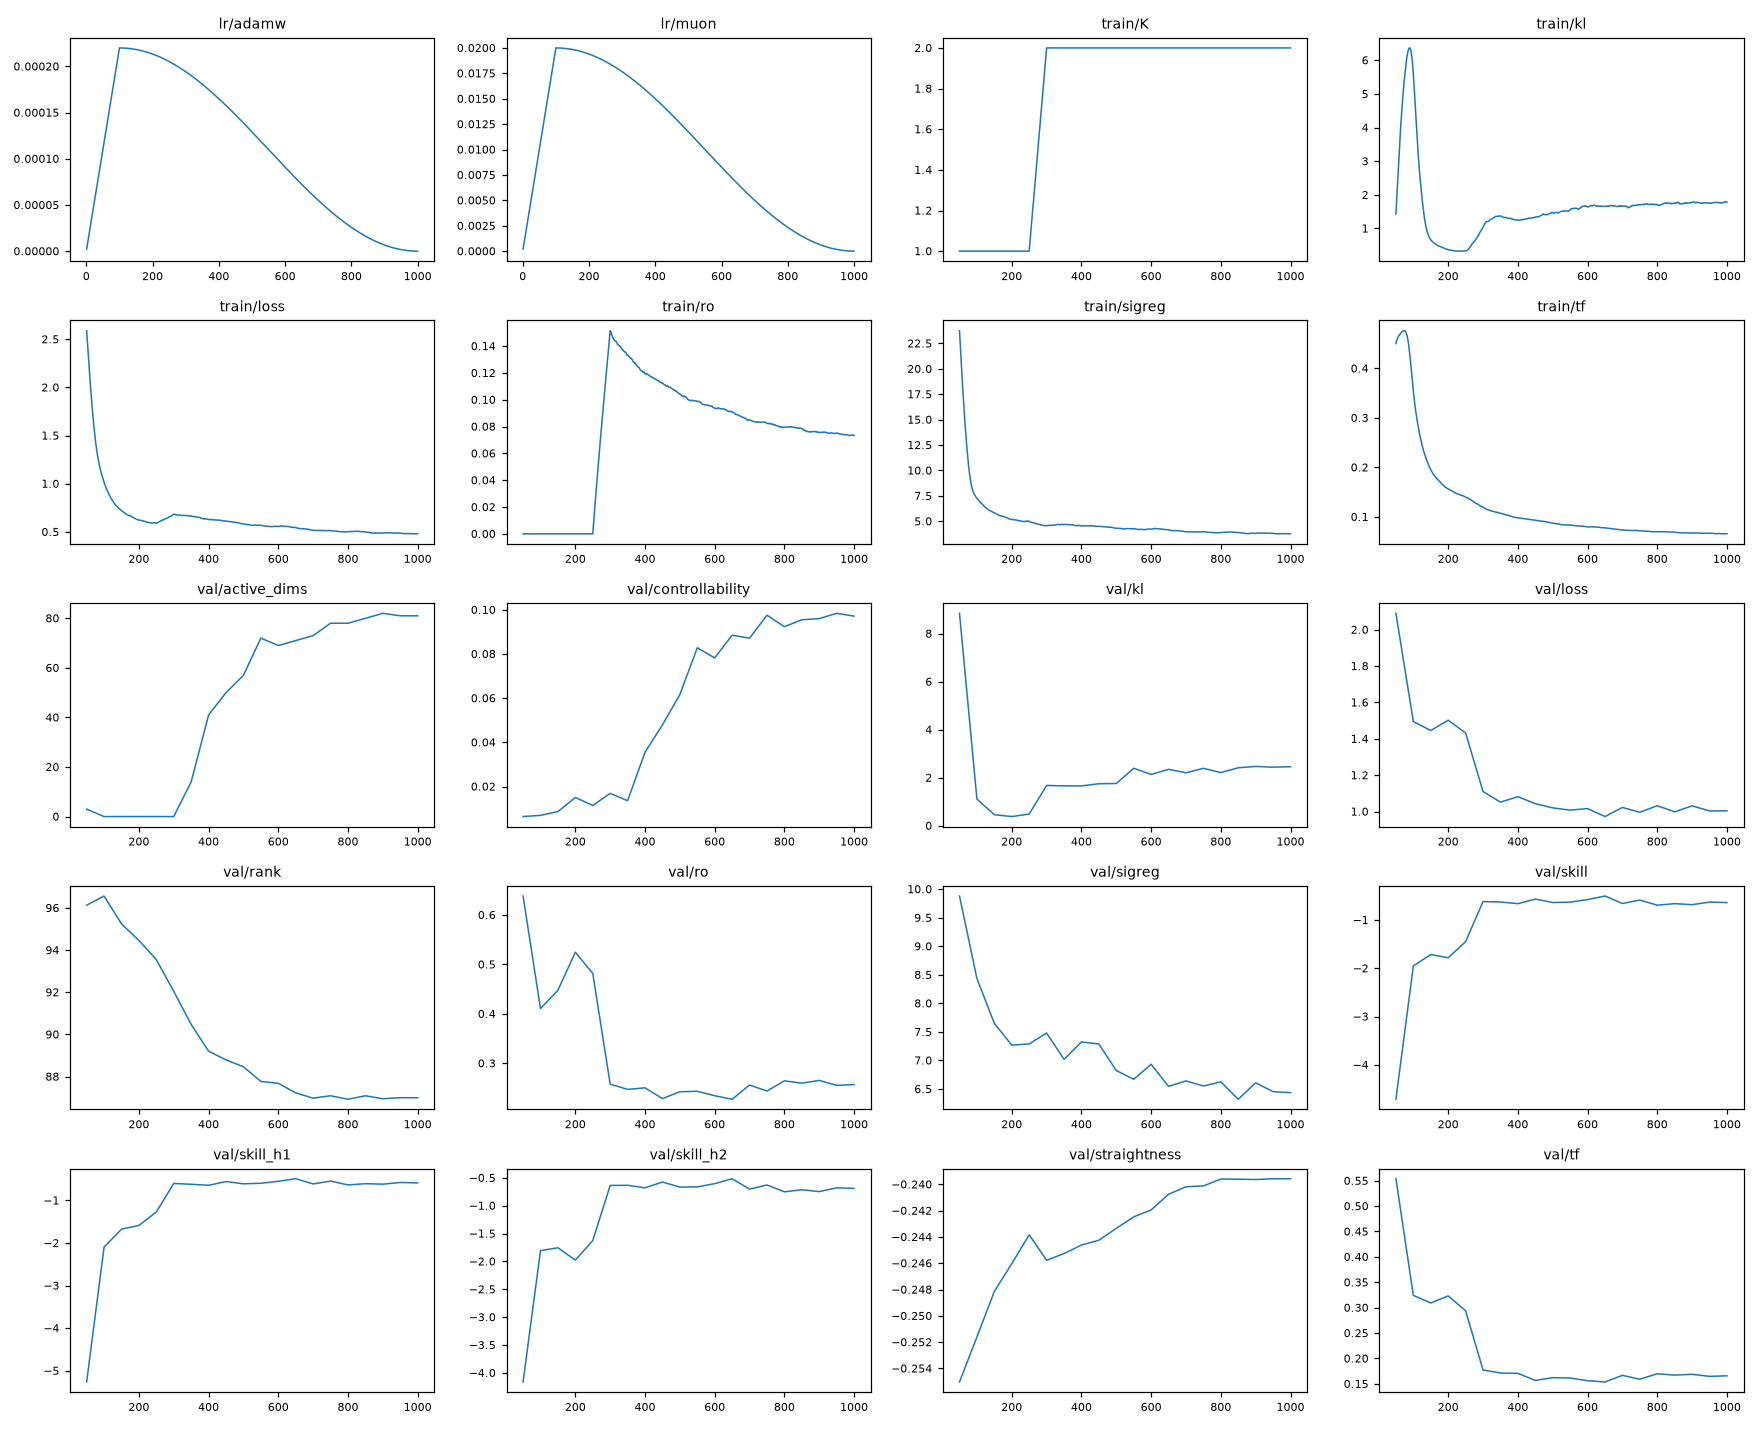

In [6]:
for run in [f"wm-phone{RUN}", f"wm-robots{RUN}"]:
    !grep -E "^step|^done" outputs/{run}/log.txt | tail -2
    display(Image(f"outputs/{run}/curves.png", width=1000))

## 3. Controllers

**Trains one controller per world model** on the same robosuite episodes (about 10 min each, after downloading them).
A controller maps a real robot action and the current frame to the world model's latent action. Log: validation loss
and `val r2` (0 = no better than always predicting the mean latent action, 1 = perfect); `best.pt` keeps the lowest
validation loss.

In [7]:
!uv run hf download batgre/h2r-sim-v3 --repo-type dataset --local-dir data/h2r-sim
for wm in ["phone", "robots"]:
    !uv run h2r controller train --set name=ctrl-{wm}{RUN} world_model=outputs/wm-{wm}{RUN} iterations={CTRL_STEPS} eval_every=100

Still waiting to acquire lock on /content/human-to-robot/data/h2r-sim/.cache/huggingface/.gitignore.lock (elapsed: 0.1 seconds)
Still waiting to acquire lock on /content/human-to-robot/data/h2r-sim/.cache/huggingface/.gitignore.lock (elapsed: 0.1 seconds)

✓ Downloaded
  path: /content/human-to-robot/data/h2r-sim



encoding train with outputs/wm-phone-h2
encoding val with outputs/wm-phone-h2
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from WANDB_API_KEY.
wandb: Currently logged in as: grevy-batsotsa (grevy-batsotsa-esme) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: ⢿ Waiting for wandb.init()...
wandb: ⣻ Waiting for wandb.init()...
wandb: ⣽ Waiting for wandb.init()...
wandb: ⣾ Waiting for wandb.init()...
wandb: ⣷ setting up run 12y4yxim (0.5s)
wandb: ⣯ setting up run 12y4yxim (0.5s)
wandb: ⣟ setting up run 12y4yxim (0.5s)
wandb: ⡿ setting up run 12y4yxim (0.5s)
wandb: ⢿ setting up run 12y4yxim (0.5s)
wandb: ⣻ setting up run 12y4yxi

**Controller curves**: training loss, validation loss and R² against the step.

done | best val loss 1.2432


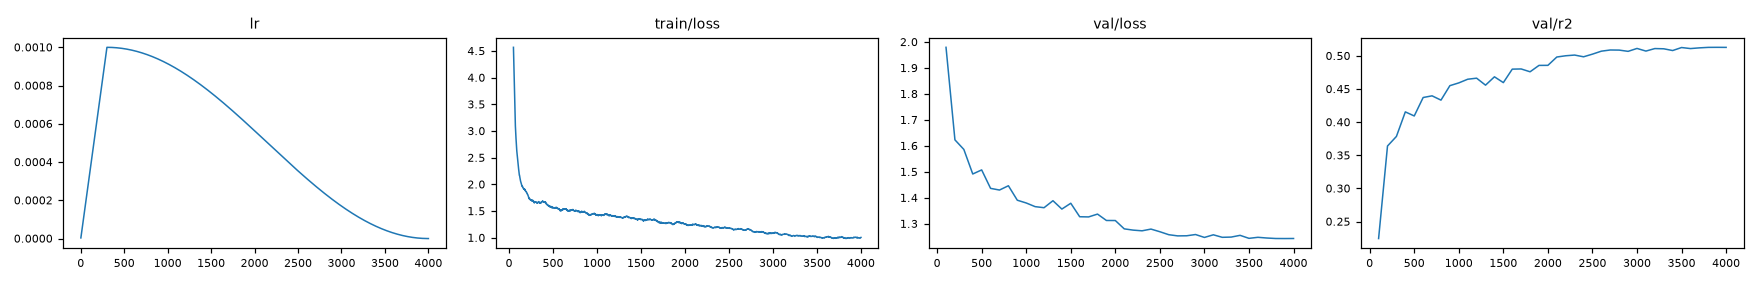

done | best val loss 1.0516


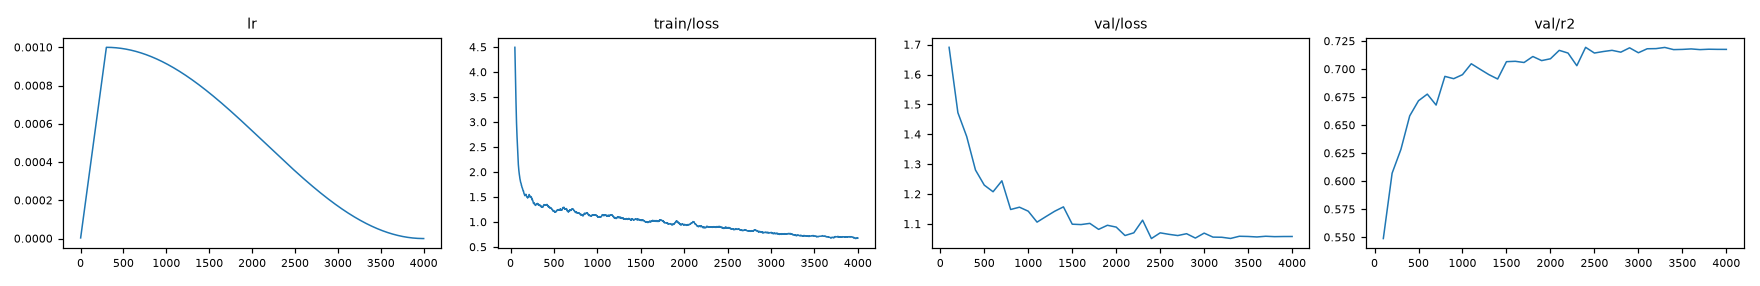

In [8]:
for run in [f"ctrl-phone{RUN}", f"ctrl-robots{RUN}"]:
    !grep -E "^done" outputs/{run}/log.txt
    display(Image(f"outputs/{run}/curves.png", width=700))

## 4. World model predictions

**Every world model on every validation set** (about 10 min): the same validation as in training, on the phone, robot
and simulation videos. The only skill numbers comparable across world models; neither model saw simulation videos,
so the `sim` row compares them on equal terms.

In [9]:
%%writefile /content/cross.py
import json
import sys

from h2r.models.jepa import load_world_model
from h2r.models.module import SIGReg
from h2r.training.utils import download_data, setup
from h2r.training.world_model import build_loaders, evaluate

DOMAINS = {"phone": {"root": "data/h2r-phone/", "hf_repo": "batgre/h2r-phone", "include": None},
           "robots": {"root": "data/h2r-robots-1h30/", "hf_repo": "batgre/h2r-robots-1h30", "include": None},
           "sim": {"root": "data/h2r-sim/", "hf_repo": "batgre/h2r-sim-v3", "include": ["Panda/Lift/*"]}}
device, autocast = setup({"seed": 0, "precision": "bf16"})
table = {}
RUN = sys.argv[1] if len(sys.argv) > 1 else ""
for wm in [f"wm-phone{RUN}", f"wm-robots{RUN}"]:
    model, cfg = load_world_model(f"outputs/{wm}", device)
    for name, data in DOMAINS.items():
        c = cfg | {"data": cfg["data"] | data | {"max_videos": None}}
        download_data(c["data"])
        m = evaluate(model, SIGReg().to(device), build_loaders(c, device)[1], c, device, autocast)
        print(f"{wm:10} on {name:7} skill h1..h{c['val_horizon']} " + " ".join(f"{m[f'skill_h{h}']:.3f}" for h in range(1, c['val_horizon'] + 1))
              + f" | controllability {m['controllability']:.3f} | rank {m['rank']:.1f} | straightness {m['straightness']:.3f}",
              flush=True)
        table[f"{wm} on {name}"] = m
json.dump(table, open(f"outputs/cross{RUN}.json", "w"), indent=2)

Writing /content/cross.py


In [10]:
# h2r lives in the uv environment, not in the notebook's Python
!uv run python /content/cross.py {RUN} 2>&1 | grep -v "Loading weights"

wm-phone-h2 on phone   skill h1..h2 0.172 0.294 | controllability 0.399 | rank 77.3 | straightness -0.213
wm-phone-h2 on robots  skill h1..h2 -1.888 -2.485 | controllability 0.082 | rank 78.8 | straightness -0.267
wm-phone-h2 on sim     skill h1..h2 -2.137 -2.445 | controllability 0.094 | rank 65.5 | straightness -0.274
wm-robots-h2 on phone   skill h1..h2 -0.778 -1.025 | controllability 0.018 | rank 91.6 | straightness -0.272
wm-robots-h2 on robots  skill h1..h2 -0.490 -0.516 | controllability 0.088 | rank 87.2 | straightness -0.241
wm-robots-h2 on sim     skill h1..h2 -2.308 -2.490 | controllability 0.039 | rank 64.3 | straightness -0.258


**Prediction on 10 simulated test episodes** (a few minutes), with each world model and its controller: skill(h)
with the IDM's latent actions (oracle, the best the world model can do), with the controller on the robot's actions,
and in the loop on its own predictions; `imagined.png` shows, for each predicted state, the nearest real frame.

In [ ]:
for wm in ["phone", "robots"]:
    !uv run h2r eval prediction --set name=diag-{wm}{RUN} controller=outputs/ctrl-{wm}{RUN} episodes=10 horizon={H}

In [ ]:
for wm in ["phone", "robots"]:
    for figure in ["prediction/skill.png", "prediction/imagined.png"]:
        display(Image(f"outputs/diag-{wm}{RUN}/{figure}", width=700))

## 5. Results archive

**Every log, curve, result and figure** in `results.zip`, downloaded to your computer.

In [15]:
!cd outputs && zip -qr /content/results.zip cross*.json */metrics.jsonl */curves.png */results.json */log.txt */metadata.json */*.png diag-*/*/*
from google.colab import files
files.download("/content/results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 6. Publish the trained models

Config, best checkpoint and curves of each run, to `batgre/h2r-lift`.

In [16]:
for run in [f"wm-phone{RUN}", f"wm-robots{RUN}", f"ctrl-phone{RUN}", f"ctrl-robots{RUN}"]:
    !uv run hf upload batgre/h2r-lift outputs/{run} {run} --include config.yaml --include best.pt --include curves.png

Found 3 files to upload
  Preparing   ████████████████████  3 / 3 ✓
  Uploading   ████████████████████  -
  Committing  ░░░░░░░░░░░░░░░░░░░░  0 / 3
  Preparing   ████████████████████  3 / 3 ✓
  Uploading   ████████████████████  -
  Committing  ░░░░░░░░░░░░░░░░░░░░  0 / 3
Traceback (most recent call last):
  File "/content/human-to-robot/.venv/bin/hf", line 10, in <module>
    sys.exit(main())
             ~~~~^^
  File "/content/human-to-robot/.venv/lib/python3.13/site-packages/huggingface_hub/cli/hf.py", line 167, in main
    app(windows_expand_args=False)
    ~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/content/human-to-robot/.venv/lib/python3.13/site-packages/click/core.py", line 1631, in __call__
    return self.main(*args, **kwargs)
           ~~~~~~~~~^^^^^^^^^^^^^^^^^
  File "/content/human-to-robot/.venv/lib/python3.13/site-packages/click/core.py", line 1552, in main
    rv = self.invoke(ctx)
  File "/content/human-to-robot/.venv/lib/python3.13/site-packages/huggingface_hub/cli/_cli

In [17]:
!uv run hf auth whoami

✓ Logged in
  user: batgre
